# Question 1

## Setup

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline

import sys
sys.path.append('../deployment')
from preprocessing import clean_text  # shared with the web app

# Folder layout: notebooks/ (this folder), ../data, ../deployment; plots go to outputs/
DATA_DIR = Path('../data')
OUT_DIR = Path('outputs')
OUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42

## 1.1 Load the data and denoise the text
### Load and inspect

In [2]:
df = pd.read_json(DATA_DIR / 'research_abstracts.json')

print("Initial data shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate abstracts:", df['Abstract'].duplicated().sum())
print("\nLabel distribution:\n", df['Label'].value_counts())

Initial data shape: (1138, 3)
Columns: ['DOI', 'Abstract', 'Label']

Missing values per column:
 DOI         4
Abstract    0
Label       0
dtype: int64

Duplicate abstracts: 13

Label distribution:
 Label
classical    900
ai           238
Name: count, dtype: int64


### Structural cleaning

In [3]:
df = df.dropna(subset=['Abstract', 'Label'])
df = df.drop_duplicates(subset='Abstract').reset_index(drop=True)
print("\nShape after removing missing/duplicate abstracts:", df.shape)


Shape after removing missing/duplicate abstracts: (1125, 3)


### Text denoising

In [4]:
df['cleaned_abstract'] = df['Abstract'].apply(clean_text)

### Evidence that denoising worked

In [5]:
# Drop rows where nothing was left after cleaning
df = df[df['cleaned_abstract'].str.strip() != ''].reset_index(drop=True)

# Evidence that denoising worked
raw_vocab = {w for t in df['Abstract'] for w in t.lower().split()}
clean_vocab = {w for t in df['cleaned_abstract'] for w in t.split()}
print("\n--- Effect of denoising ---")
print(f"Average tokens per abstract: {df['Abstract'].str.split().str.len().mean():.1f}"
      f" -> {df['cleaned_abstract'].str.split().str.len().mean():.1f}")
print(f"Vocabulary size:            {len(raw_vocab)} -> {len(clean_vocab)}")
print("Abstracts still containing 'copyright':",
      df['cleaned_abstract'].str.contains('copyright').sum())


--- Effect of denoising ---
Average tokens per abstract: 171.6 -> 104.5
Vocabulary size:            17734 -> 8297
Abstracts still containing 'copyright': 0


## 1.2 Identify relevant columns and engineer features
### Column relevance

In [6]:
# DOI is only an identifier (says nothing about the content) -> dropped
# Abstract is the input feature, Label is the target
print(f"DOI: {df['DOI'].nunique()} unique values in {len(df)} rows -> identifier, dropped")
print("Abstract -> input feature")
print(f"Label {sorted(df['Label'].unique())} -> target")

X = df['cleaned_abstract']
y = df['Label']

DOI: 1123 unique values in 1125 rows -> identifier, dropped
Abstract -> input feature
Label ['ai', 'classical'] -> target


### Train-test split

In [7]:
# Split before fitting the vectoriser so no test data leaks into the features;
# stratify keeps the ai/classical ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Training set: {len(X_train)} | Test set: {len(X_test)}")

Training set: 900 | Test set: 225


### Feature modelling: TF-IDF (unigrams + bigrams)

In [8]:
# TF-IDF weights words that are frequent in an abstract but rare across abstracts;
# bigrams capture terms such as "neural network" and "machine learning"
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=5000,
                             sublinear_tf=True)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
print("TF-IDF matrix (train):", X_train_vec.shape)

TF-IDF matrix (train): (900, 5000)


### Most relevant terms (chi-square)

In [9]:
chi2_scores, _ = chi2(X_train_vec, y_train)
top_terms = pd.Series(chi2_scores, index=vectorizer.get_feature_names_out()).nlargest(15)
print(top_terms.round(1).to_string())

machine             19.4
network             19.2
neural              17.9
neural network      17.7
machine learning    17.5
learning            17.3
algorithm           13.1
lstm                 8.7
quantile             8.6
svr                  8.3
forest               7.8
sentiment            7.4
learning model       7.4
artificial           7.4
random forest        7.3


## 1.3 Baseline model and performance report
### Majority-class reference

In [10]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train_vec, y_train)
y_dummy = dummy.predict(X_test_vec)
print("\n=== MAJORITY-CLASS REFERENCE ===")
print(f"Accuracy: {accuracy_score(y_test, y_dummy):.4f}   "
      f"Macro F1: {f1_score(y_test, y_dummy, average='macro'):.4f}")


=== MAJORITY-CLASS REFERENCE ===
Accuracy: 0.7911   Macro F1: 0.4417


### Baseline: Logistic Regression

In [11]:
# 5-fold stratified cross-validation on the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    'LogReg (default)':  LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'LogReg (balanced)': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                            class_weight='balanced'),
}

results = {}
for name, clf in models.items():
    pipe = Pipeline([
        ('vec', clone(vectorizer)),
        ('clf', clf),
    ])

    # Model learning vs generalisation: training-fold vs validation-fold scores
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring='f1_macro',
                            return_train_score=True)

    # Final fit on the full training set, evaluated once on the held-out test set
    pipe.fit(X_train, y_train)
    y_train_pred = pipe.predict(X_train)
    y_pred = pipe.predict(X_test)

    results[name] = {
        'pipe': pipe,
        'y_pred': y_pred,
        'cv_train_f1': cv_res['train_score'].mean(),
        'cv_val_f1': cv_res['test_score'].mean(),
        'train_acc': accuracy_score(y_train, y_train_pred),
        'test_acc': accuracy_score(y_test, y_pred),
        'train_f1': f1_score(y_train, y_train_pred, average='macro'),
        'test_f1': f1_score(y_test, y_pred, average='macro'),
        'ai_recall': classification_report(y_test, y_pred, output_dict=True)['ai']['recall'],
    }

    print(f"\n=== {name.upper()} ===")
    print(f"5-fold CV macro F1  - train folds: {cv_res['train_score'].mean():.3f}, "
          f"validation folds: {cv_res['test_score'].mean():.3f} "
          f"(+/- {cv_res['test_score'].std():.3f})")
    print(f"Accuracy            - train: {results[name]['train_acc']:.3f}, "
          f"test: {results[name]['test_acc']:.3f}")
    print(f"Macro F1            - train: {results[name]['train_f1']:.3f}, "
          f"test: {results[name]['test_f1']:.3f}")
    print("\nTest-set classification report:")
    print(classification_report(y_test, y_pred, digits=3))


=== LOGREG (DEFAULT) ===
5-fold CV macro F1  - train folds: 0.778, validation folds: 0.683 (+/- 0.063)
Accuracy            - train: 0.896, test: 0.858
Macro F1            - train: 0.802, test: 0.701

Test-set classification report:
              precision    recall  f1-score   support

          ai      1.000     0.319     0.484        47
   classical      0.848     1.000     0.918       178

    accuracy                          0.858       225
   macro avg      0.924     0.660     0.701       225
weighted avg      0.879     0.858     0.827       225




=== LOGREG (BALANCED) ===
5-fold CV macro F1  - train folds: 0.977, validation folds: 0.837 (+/- 0.007)
Accuracy            - train: 0.980, test: 0.907
Macro F1            - train: 0.970, test: 0.862

Test-set classification report:
              precision    recall  f1-score   support

          ai      0.760     0.809     0.784        47
   classical      0.949     0.933     0.941       178

    accuracy                          0.907       225
   macro avg      0.854     0.871     0.862       225
weighted avg      0.909     0.907     0.908       225



### Performance summary

In [12]:
summary = pd.DataFrame(results).T[['train_acc', 'test_acc', 'train_f1', 'test_f1',
                                   'cv_train_f1', 'cv_val_f1', 'ai_recall']]
summary.loc['Majority class'] = [
    accuracy_score(y_train, dummy.predict(X_train_vec)),
    accuracy_score(y_test, y_dummy),
    f1_score(y_train, dummy.predict(X_train_vec), average='macro'),
    f1_score(y_test, y_dummy, average='macro'),
    np.nan, np.nan, 0.0,
]
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
print("\n=== PERFORMANCE SUMMARY ===")
print(summary.astype(float).round(3))


=== PERFORMANCE SUMMARY ===
                   train_acc  test_acc  train_f1  test_f1  cv_train_f1  cv_val_f1  ai_recall
LogReg (default)       0.896     0.858     0.802    0.701        0.778      0.683      0.319
LogReg (balanced)      0.980     0.907     0.970    0.862        0.977      0.837      0.809
Majority class         0.791     0.791     0.442    0.442          NaN        NaN      0.000


### Confusion matrices (test set)

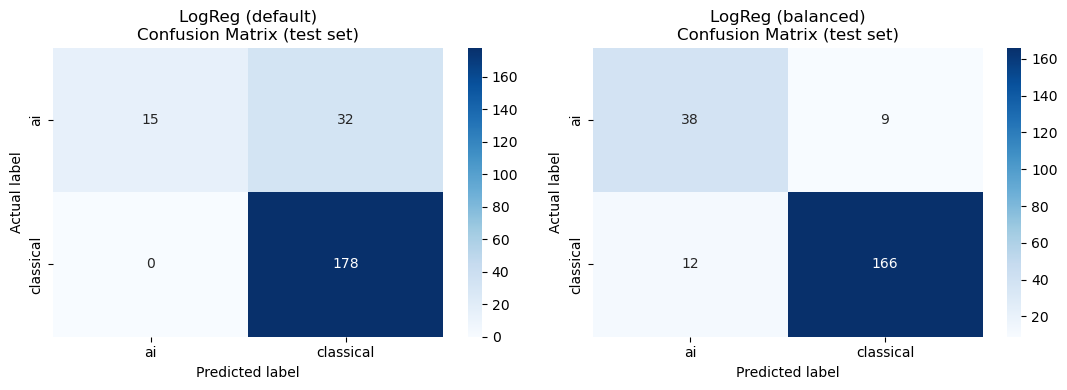

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res['y_pred'], labels=['ai', 'classical'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['ai', 'classical'], yticklabels=['ai', 'classical'])
    ax.set_title(f'{name}\nConfusion Matrix (test set)')
    ax.set_ylabel('Actual label')
    ax.set_xlabel('Predicted label')
plt.tight_layout()
plt.savefig(OUT_DIR / 'q1_confusion_matrices.png', dpi=150)
plt.show()

### Learning curve

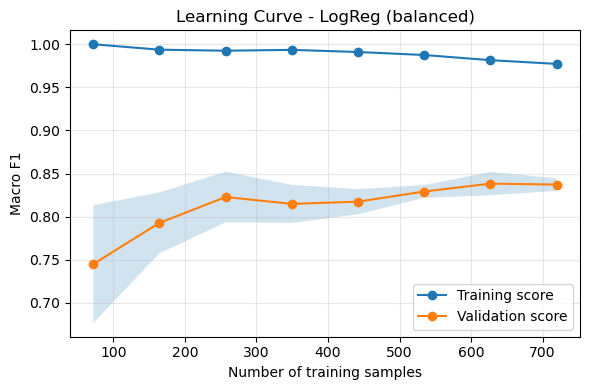

In [14]:
# Learning curve for the balanced model: how training and validation scores
# change as more training data is used (diagnoses over/underfitting)
best_pipe = results['LogReg (balanced)']['pipe']
train_sizes, train_scores, val_scores = learning_curve(
    best_pipe, X_train, y_train, cv=cv, scoring='f1_macro',
    train_sizes=np.linspace(0.1, 1.0, 8), random_state=RANDOM_STATE
)
plt.figure(figsize=(6, 4))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Training score')
plt.plot(train_sizes, val_scores.mean(axis=1), 'o-', label='Validation score')
plt.fill_between(train_sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.2)
plt.xlabel('Number of training samples')
plt.ylabel('Macro F1')
plt.title('Learning Curve - LogReg (balanced)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / 'q1_learning_curve.png', dpi=150)
plt.show()